# 02 — Modeling, Error Diagnosis & Architecture Benchmark

**Project:** `spain-electricity-forecast` (24h-Ahead Peninsular Spain Hourly Electricity Demand)  
**Objective:** Audit the trained `LightGBM` model artifact on the out-of-time test set (`July 1 – October 31, 2026`), inspect feature importance and residual patterns across local hours and days of the week, and benchmark performance against a naive weekly baseline and `XGBoost`.


## 1. Load Feature Dataset, Model Artifact & Out-of-Time Predictions

We load the leak-free `features.parquet` table and the serialized `LightGBM` artifact produced by `src.train`, reconstruct the strict chronological split (`Train < 2026-01-01`, `Val: 2026-01-01 to 2026-06-30`, `Test >= 2026-07-01`), and compute residuals (`Actual - Predicted`) on the unseen test period.


In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import FEATURES_DATA_PATH, MODEL_OUTPUT_PATH, TARGET_COL
from src.train import compute_metrics, split_temporal_data

sns.set_theme(style="whitegrid", context="notebook")

# Load features and saved model artifact
df = pd.read_parquet(FEATURES_DATA_PATH)
artifact = joblib.load(MODEL_OUTPUT_PATH)
lgbm_model = artifact["model"]
feature_cols = artifact["feature_cols"]

train_df, val_df, test_df = split_temporal_data(df)

# Generate predictions on the out-of-time Test set
test_df = test_df.copy()
test_df["pred_lgbm"] = lgbm_model.predict(test_df[feature_cols])
test_df["residual"] = test_df[TARGET_COL] - test_df["pred_lgbm"]
test_df["abs_error"] = test_df["residual"].abs()
test_df["local_dt"] = test_df["timestamp_utc"].dt.tz_convert("Europe/Madrid")

print("Test Metrics LightGBM:", compute_metrics(test_df[TARGET_COL], test_df["pred_lgbm"]))


2026-11-17 14:45:36,098 - INFO - Temporal Split -> Train: 34873 rows | Val: 4344 rows | Test: 2951 rows


Test Metrics LightGBM: {'mae_mwh': 537.66, 'rmse_mwh': 714.69, 'mape_pct': 1.837}


## 2. Visual Forecast Inspection: Actual vs. Predicted Demand (Summer Peak Window)

To verify how closely the 24h-ahead forecast tracks intraday peaks, overnight troughs, and the weekend drop, we zoom into a two-week summer window (`July 6–20, 2026`) and compare `LightGBM` against the naive weekly persistence baseline (`demand_lag_168h`).


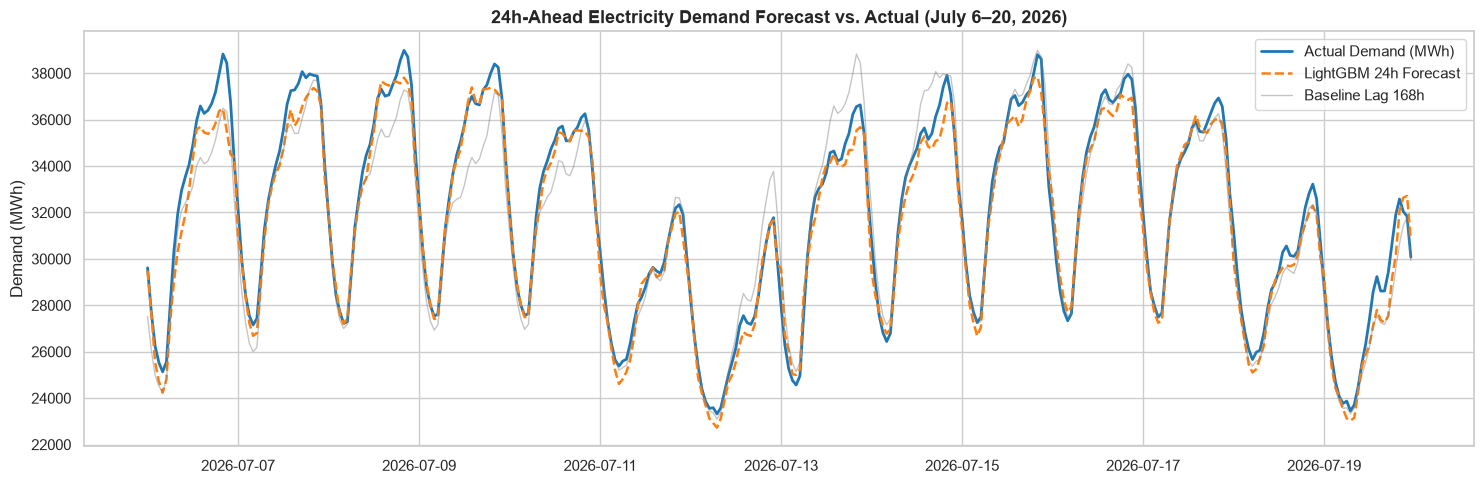

In [2]:
# Inspect a 14-day window in July 2026 (peak summer cooling load)
zoom_mask = (test_df["local_dt"] >= "2026-07-06") & (test_df["local_dt"] < "2026-07-20")
zoom_df = test_df.loc[zoom_mask]

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(zoom_df["local_dt"], zoom_df[TARGET_COL], label="Actual Demand (MWh)", color="#1f77b4", linewidth=2)
ax.plot(zoom_df["local_dt"], zoom_df["pred_lgbm"], label="LightGBM 24h Forecast", color="#ff7f0e", linestyle="--", linewidth=1.8)
ax.plot(zoom_df["local_dt"], zoom_df["demand_lag_168h"], label="Baseline Lag 168h", color="gray", alpha=0.45, linewidth=1)

ax.set_title("24h-Ahead Electricity Demand Forecast vs. Actual (July 6–20, 2026)", fontsize=13, fontweight="bold")
ax.set_ylabel("Demand (MWh)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


## 3. Feature Importance Analysis (Split Gain)

Unlike split count, **total gain** measures the actual reduction in loss contributed by each predictor across all trees. This validates whether our domain-engineered features—weekly momentum (`demand_diff_24h_168h`), national holidays (`is_holiday`), and thermal inertia (`temp_roll_mean_24h`)—drive predictive accuracy beyond raw autoregressive lags.


/var/folders/0q/1g3jzg9573n9lzs_nq11tjjh0000gn/T/ipykernel_74864/3679197247.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df.head(15), x="gain", y="feature", palette="viridis", ax=ax)


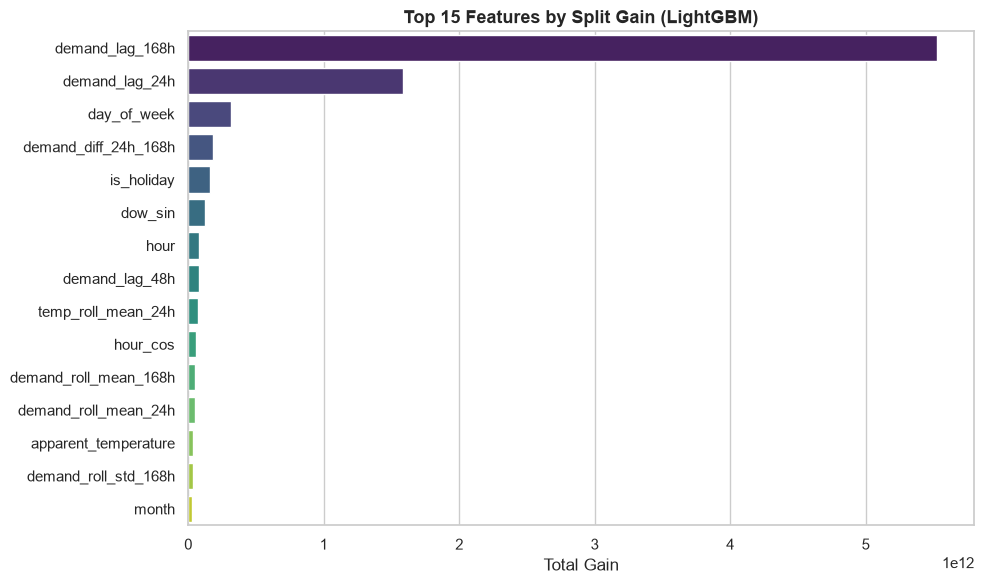

In [3]:
importance_df = pd.DataFrame({
    "feature": feature_cols,
    "gain": lgbm_model.booster_.feature_importance(importance_type="gain"),
}).sort_values("gain", ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=importance_df.head(15), x="gain", y="feature", palette="viridis", ax=ax)
ax.set_title("Top 15 Features by Split Gain (LightGBM)", fontsize=13, fontweight="bold")
ax.set_xlabel("Total Gain")
ax.set_ylabel("")
plt.tight_layout()
plt.show()


## 4. Residual Diagnostics & Worst-Case Error Audit

Aggregate metrics (`MAE`, `RMSE`, `MAPE`) can mask systematic biases during specific hours, weekend transitions, or national holidays. Below we inspect:
1. **Residual distribution** to verify zero-centered, unbiased predictions.
2. **MAE by local hour (`Europe/Madrid`)** to check morning ramp-up and midday solar/cooling peaks.
3. **MAE by day of week** and the **top 5 largest single-hour errors** in the test set.


2026-11-17 14:48:11,505 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-17 14:48:11,506 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


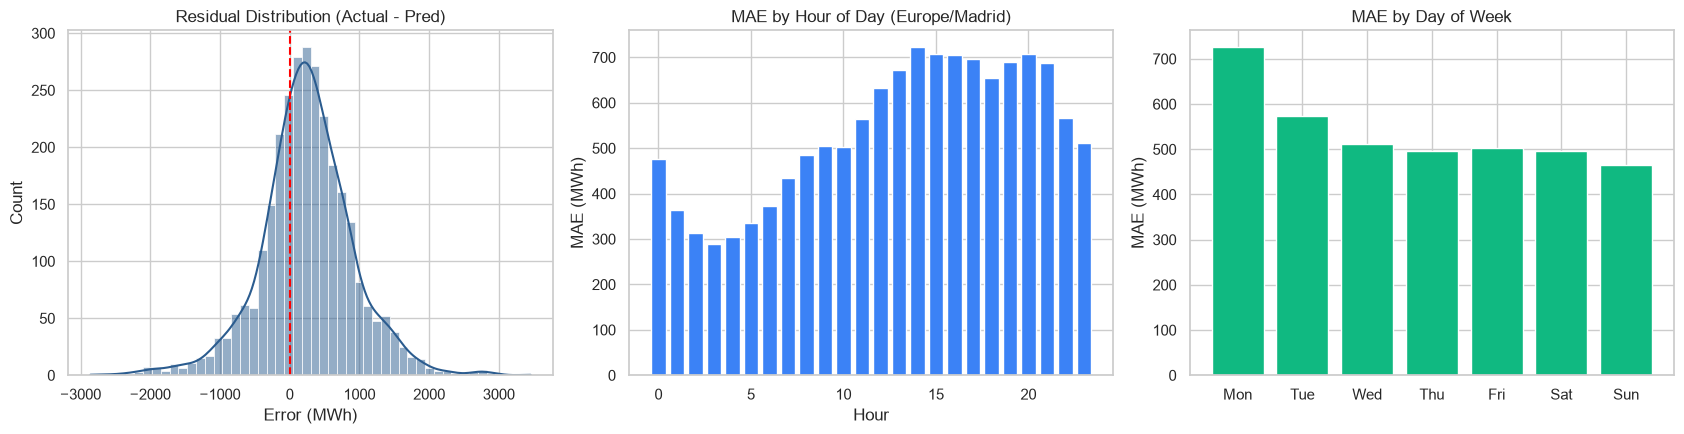

Top 5 Largest Errors in Test Set:


,local_dt,is_holiday,demand_mwh,pred_lgbm,residual
40868,2026-09-07 21:00:00+02:00,0,38218.55,34762.391370,3456.158630
41731,2026-10-13 20:00:00+02:00,0,32860.94,29907.385761,2953.554239
39356,2026-07-06 21:00:00+02:00,0,38441.65,35517.866373,2923.783627
40933,2026-09-10 14:00:00+02:00,0,29662.01,32521.881840,-2859.871840
40813,2026-09-05 14:00:00+02:00,0,31794.33,28948.912289,2845.417711


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1. Residual distribution (check bias around 0)
sns.histplot(test_df["residual"], bins=50, kde=True, ax=axes[0], color="#2b5c8f")
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_title("Residual Distribution (Actual - Pred)")
axes[0].set_xlabel("Error (MWh)")

# 2. MAE by local hour of the day
hourly_mae = test_df.groupby("hour")["abs_error"].mean()
axes[1].bar(hourly_mae.index, hourly_mae.values, color="#3b82f6")
axes[1].set_title("MAE by Hour of Day (Europe/Madrid)")
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("MAE (MWh)")

# 3. MAE by day of week (0=Mon ... 6=Sun)
dow_mae = test_df.groupby("day_of_week")["abs_error"].mean()
axes[2].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow_mae.values, color="#10b981")
axes[2].set_title("MAE by Day of Week")
axes[2].set_ylabel("MAE (MWh)")

plt.tight_layout()
plt.show()

# Inspect the 5 worst hourly errors in Test (often national holidays like Aug 15 or Oct 12)
worst_errors = test_df.nlargest(5, "abs_error")[["local_dt", "is_holiday", TARGET_COL, "pred_lgbm", "residual"]]
print("Top 5 Largest Errors in Test Set:")
display(worst_errors)


## 5. Model Architecture Benchmark: LightGBM vs. XGBoost

Finally, we train an `XGBoost` regressor using the exact same chronological split, early stopping rule (`50` rounds on validation MAE), and feature set to confirm whether histogram-based leaf-wise boosting (`LightGBM`) or depth-wise boosting (`XGBoost`) generalizes better on this tabular time-series problem.


In [5]:
import xgboost as xgb

xgb_model = xgb.XGBRegressor(
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    early_stopping_rounds=50,
    eval_metric="mae",
    random_state=42,
    n_jobs=-1,
)

xgb_model.fit(
    train_df[feature_cols],
    train_df[TARGET_COL],
    eval_set=[(val_df[feature_cols], val_df[TARGET_COL])],
    verbose=200,
)

xgb_test_preds = xgb_model.predict(test_df[feature_cols])
comparison = pd.DataFrame({
    "Baseline (Lag 168h)": compute_metrics(test_df[TARGET_COL], test_df["demand_lag_168h"]),
    "LightGBM": compute_metrics(test_df[TARGET_COL], test_df["pred_lgbm"]),
    "XGBoost": compute_metrics(test_df[TARGET_COL], xgb_test_preds),
}).T

display(comparison)


[0]	validation_0-mae:3677.10852
[200]	validation_0-mae:655.41198
[400]	validation_0-mae:611.05354
[600]	validation_0-mae:601.50858
[710]	validation_0-mae:600.49908


,mae_mwh,rmse_mwh,mape_pct
Baseline (Lag 168h),1405.32,1955.82,4.944
LightGBM,537.66,714.69,1.837
XGBoost,554.56,733.30,1.897
